# Modeling and Evaluation
This file is for the actual building of the movie ratings classification model as well as the evaluation of the model on the test set.

### Packages and Test/Train Set Up
Import the packages below. Upload the rt_reviews_subset.csv data file from the repository to Colab files panel on the left side to be able to read in the data.

In [ ]:
import pandas as pd
import torch
from transformers import pipeline
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split

In [ ]:
#Read In Data
df = pd.read_csv('rt_reviews_subset.csv')
print(df.head())

#Test Train Split 70%/30%
train_df, test_df = train_test_split(df, test_size=0.3, random_state=2026, stratify=df['Freshness'])
print(f"Training set size: {len(train_df)}")
print(f"Testing set size: {len(test_df)}")

   Row_ID Freshness                                             Review
0       1    rotten   For all Anderson's pleasing, refreshing auteu...
1       2     fresh   For all the artists that populate Hong Sang-s...
2       3    rotten   A critic needs only two words to dispense wit...
3       4    rotten   This doesn't seem like a movie of passion or ...
4       5     fresh   I can't think of another movie that captures ...
Training set size: 2100
Testing set size: 900


### Model Pipeline

Data is split into training and testing sets. A classifier will be built using a Hugging Face pipeline to map positive sentiment to "Fresh" and negative sentiment to "Rotten" classifications.

In [ ]:
#Building classifier
classifier = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english", device=0 if torch.cuda.is_available() else -1)

#Run predictions on the test set
reviews = test_df['Review'].tolist()
predictions = classifier(reviews, truncation=True)

#Map predictions to 'Fresh' and 'Rotten'
y_pred = ['fresh' if pred['label'] == 'POSITIVE' else 'rotten' for pred in predictions]
y_true = test_df['Freshness'].tolist()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

### Model Evaluation

We evaluate the classification model using precision, recall, F1-score, and a confusion matrix.

Classification Report:

              precision    recall  f1-score   support

       fresh       0.86      0.85      0.85       501
      rotten       0.81      0.83      0.82       399

    accuracy                           0.84       900
   macro avg       0.84      0.84      0.84       900
weighted avg       0.84      0.84      0.84       900



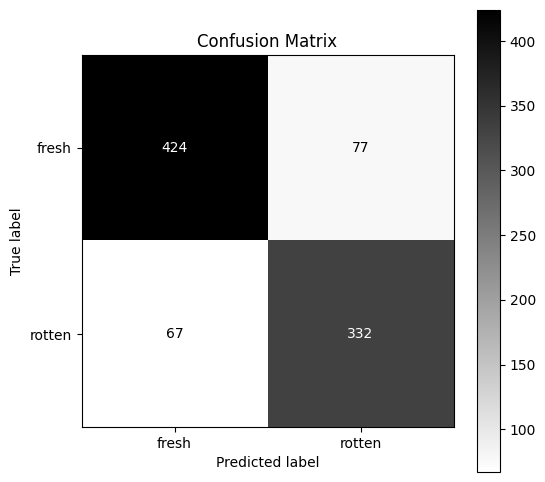

In [ ]:
#Print classification report
print("Classification Report:\n")
print(classification_report(y_true, y_pred))

#Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=['fresh', 'rotten'], cmap='binary', ax=ax)
plt.title('Confusion Matrix')
plt.show()